In [5]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from src.ingestion import load_tml_seasons
from src.elo import (
    compute_dynamic_elo,
    attach_elo_to_long,
    fit_opponent_adjusted_tpw,
    summarize_sos_and_adjusted,
    bootstrap_adjusted_diff,
)

# 1. Calentar Elo desde 2018 para evitar ruido inicial en 2021
raw_all = load_tml_seasons("../data/raw", years=range(2018, 2027))
elo_matches = compute_dynamic_elo(raw_all, blend_weight=0.5)

# 2. Cruzar con el dataset procesado del Bloque 1 (2021-2026)
long_df = pd.read_parquet("../data/processed/atp_long_2021_2026.parquet")
long_with_elo = attach_elo_to_long(long_df, elo_matches)

# 3. Ajustar modelo de rendimiento ajustado por calidad del rival
df_adj, wls_model = fit_opponent_adjusted_tpw(long_with_elo)
print(wls_model.summary().tables[1])

# Guardar para Bloque 3 y 4
df_adj.to_parquet("../data/processed/atp_long_with_elo_2021_2026.parquet", index=False)

# 4. Auditoría de Zverev: calendario vs. nivel ajustado (2021-2026)
zverev_sos = summarize_sos_and_adjusted(df_adj, "Alexander Zverev")
display(zverev_sos.round(2))

# Zoom clave: solo rondas finales (QF, SF, F) en Grand Slams y Masters 1000
late_rounds = df_adj[
    df_adj["tourney_level"].isin(["G", "M"]) & df_adj["round"].isin(["QF", "SF", "F"])
]
display(summarize_sos_and_adjusted(late_rounds, "Alexander Zverev").round(2))

# 5. Contraste estadístico: ¿jugó realmente mejor en 2026 ajustando por rival?
print("2024 vs 2026:", bootstrap_adjusted_diff(df_adj, "Alexander Zverev", 2024, 2026))
print("2025 vs 2026:", bootstrap_adjusted_diff(df_adj, "Alexander Zverev", 2025, 2026))

# 6. Comparativa directa en 2026 frente a Sinner y Alcaraz
big3_2026 = pd.concat([
    summarize_sos_and_adjusted(df_adj[df_adj["season"] == 2026], p).assign(player=p)
    for p in ["Alexander Zverev", "Jannik Sinner", "Carlos Alcaraz"]
], ignore_index=True)
display(big3_2026[["player", "matches", "peak_elo_overall", "avg_opp_elo", "raw_tpw_pct", "adj_tpw_plus"]].round(2))

                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              63.9833      0.317    201.986      0.000      63.362      64.604
C(surface)[T.Grass]    -0.1503      0.100     -1.508      0.132      -0.346       0.045
C(surface)[T.Hard]      0.2256      0.067      3.377      0.001       0.095       0.357
C(best_of)[T.5]         0.1394      0.068      2.047      0.041       0.006       0.273
opp_elo_blend          -0.0085      0.000    -44.849      0.000      -0.009      -0.008


,season,matches,peak_elo_overall,end_elo_overall,avg_opp_elo,elite_matches_2000p,elite_win_pct,raw_tpw_pct,expected_tpw_pct,adj_tpw_plus
0,2021,67.0,2063.70,2063.70,1758.73,11.0,27.27,53.41,49.21,4.20
1,2022,37.0,2087.59,2033.00,1752.57,5.0,40.00,52.54,49.30,3.24
2,2023,80.0,2023.16,1936.17,1726.03,8.0,25.00,51.73,49.52,2.20
3,2024,88.0,2011.17,2011.17,1747.23,6.0,33.33,53.41,49.30,4.12
4,2025,80.0,2038.69,1951.09,1758.50,7.0,14.29,52.23,49.30,2.94
5,2026,86.0,2044.81,2037.42,1787.80,8.0,0.00,53.20,49.06,4.14


,season,matches,peak_elo_overall,end_elo_overall,avg_opp_elo,elite_matches_2000p,elite_win_pct,raw_tpw_pct,expected_tpw_pct,adj_tpw_plus
0,2021,15.0,2057.84,2057.84,1948.47,6.0,16.67,51.31,47.58,3.73
1,2022,10.0,2033.00,2033.00,1948.62,5.0,40.00,50.00,47.47,2.53
2,2023,5.0,1963.32,1963.32,1936.38,2.0,0.00,48.55,47.78,0.76
3,2024,18.0,2010.96,1980.40,1918.67,5.0,20.00,51.51,47.80,3.71
4,2025,11.0,2038.69,1949.27,1998.58,5.0,20.00,48.75,47.58,1.17
5,2026,22.0,2044.81,2043.67,1952.62,6.0,0.00,52.37,47.67,4.70


2024 vs 2026: {'adj_tpw_2024': np.float64(4.12), 'adj_tpw_2026': np.float64(4.14), 'diff_pp': np.float64(0.03), 'ci_95': (np.float64(-1.14), np.float64(1.16)), 'p_value': np.float64(0.9792), 'significant_95': False}
2025 vs 2026: {'adj_tpw_2025': np.float64(2.94), 'adj_tpw_2026': np.float64(4.14), 'diff_pp': np.float64(1.21), 'ci_95': (np.float64(-0.1), np.float64(2.46)), 'p_value': np.float64(0.0688), 'significant_95': False}


,player,matches,peak_elo_overall,avg_opp_elo,raw_tpw_pct,adj_tpw_plus
0,Alexander Zverev,86.0,2044.81,1787.80,53.20,4.14
1,Jannik Sinner,47.0,2291.38,1773.38,55.87,6.78
2,Carlos Alcaraz,52.0,2245.26,1803.10,54.23,5.32


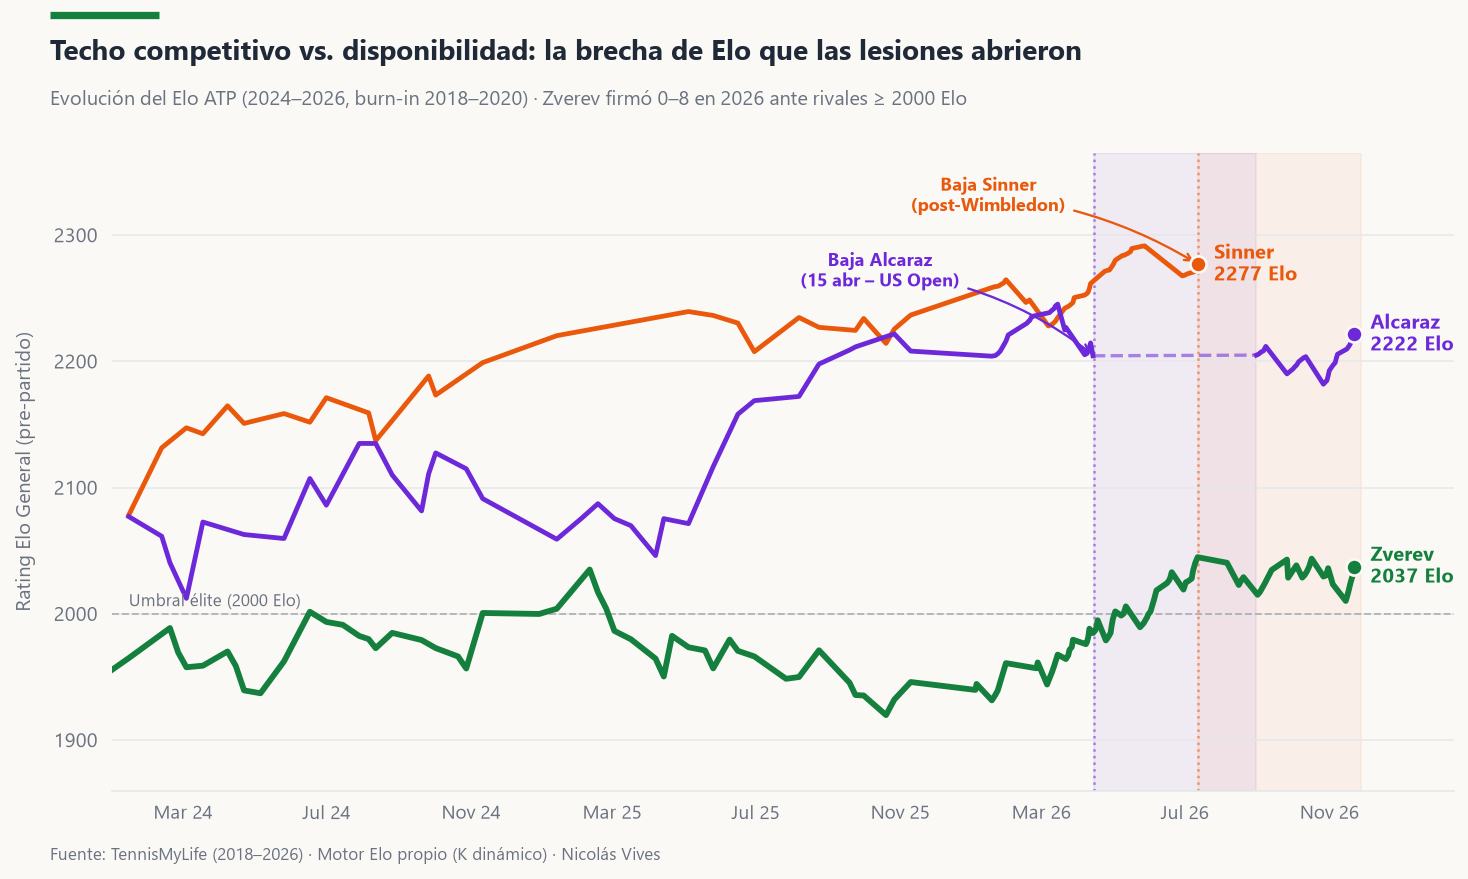

In [7]:
from src.viz import PALETTE, apply_editorial_style, add_editorial_chrome, save_figure

apply_editorial_style()

players = {
    "Jannik Sinner": PALETTE["sinner"],
    "Carlos Alcaraz": PALETTE["alcaraz"],
    "Alexander Zverev": PALETTE["zverev"],
}
ALCARAZ_INJURY_DATE = pd.Timestamp("2026-04-15")

plot_df = df_adj[
    (df_adj["season"] >= 2024) & (df_adj["player_name"].isin(players.keys()))
].sort_values("tourney_date")

fig, ax = plt.subplots(figsize=(10.4, 6.0))
ax.spines["left"].set_visible(False)
ax.grid(axis="x", visible=False)

end_points = {}
alcaraz_pre_elo = None

for name, color in players.items():
    sub = plot_df[plot_df["player_name"] == name]
    tourney_elo = (
        sub.groupby("tourney_date", as_index=False)["player_elo_overall"]
        .last()
        .sort_values("tourney_date")
    )
    lw = 2.8 if name == "Alexander Zverev" else 2.3

    if name == "Carlos Alcaraz":
        before = tourney_elo[tourney_elo["tourney_date"] <= ALCARAZ_INJURY_DATE]
        after = tourney_elo[tourney_elo["tourney_date"] > ALCARAZ_INJURY_DATE]

        ax.plot(before["tourney_date"], before["player_elo_overall"], color=color, lw=lw, zorder=3)
        if not after.empty:
            ax.plot(after["tourney_date"], after["player_elo_overall"], color=color, lw=lw, zorder=3)
            last_pre, first_post = before.iloc[-1], after.iloc[0]
            alcaraz_pre_elo = last_pre["player_elo_overall"]

            ax.plot(
                [last_pre["tourney_date"], first_post["tourney_date"]],
                [last_pre["player_elo_overall"], first_post["player_elo_overall"]],
                color=color, lw=1.6, linestyle="--", alpha=0.55, zorder=2,
            )
            ax.axvspan(ALCARAZ_INJURY_DATE, first_post["tourney_date"], color=color, alpha=0.07, zorder=0)
    else:
        ax.plot(tourney_elo["tourney_date"], tourney_elo["player_elo_overall"], color=color, lw=lw, zorder=3)

    last_row = tourney_elo.iloc[-1]
    end_points[name] = (last_row["tourney_date"], last_row["player_elo_overall"])
    ax.scatter(
        last_row["tourney_date"], last_row["player_elo_overall"],
        color=color, s=60, edgecolors=PALETTE["bg"], lw=1.3, zorder=5,
    )

# Etiquetas directas al final de cada serie (sin caja de leyenda)
for name, (dt, val) in end_points.items():
    short = name.split()[-1]
    ax.text(
        dt + pd.Timedelta(days=14), val,
        f"{short}\n{val:.0f} Elo",
        color=players[name], fontsize=9.5, fontweight="bold", va="center", ha="left",
    )

# Bandas y anotaciones limpias de las lesiones
if alcaraz_pre_elo is not None:
    ax.axvline(ALCARAZ_INJURY_DATE, color=PALETTE["alcaraz"], linestyle=":", alpha=0.55, lw=1.2)
    ax.annotate(
        "Baja Alcaraz\n(15 abr – US Open)",
        xy=(ALCARAZ_INJURY_DATE, alcaraz_pre_elo),
        xytext=(pd.Timestamp("2025-10-15"), alcaraz_pre_elo + 55),
        arrowprops=dict(arrowstyle="->", color=PALETTE["alcaraz"], lw=1.1, connectionstyle="arc3,rad=-0.15"),
        fontsize=8.6, fontweight="bold", color=PALETTE["alcaraz"], ha="center",
    )

sinner_dt, sinner_val = end_points["Jannik Sinner"]
ax.axvline(sinner_dt, color=PALETTE["sinner"], linestyle=":", alpha=0.55, lw=1.2)
ax.axvspan(sinner_dt, pd.Timestamp("2026-11-28"), color=PALETTE["sinner"], alpha=0.06, zorder=0)
ax.annotate(
    "Baja Sinner\n(post-Wimbledon)",
    xy=(sinner_dt, sinner_val),
    xytext=(pd.Timestamp("2026-01-15"), sinner_val + 42),
    arrowprops=dict(arrowstyle="->", color=PALETTE["sinner"], lw=1.1, connectionstyle="arc3,rad=-0.12"),
    fontsize=8.6, fontweight="bold", color=PALETTE["sinner"], ha="center",
)

# Referencia sutil de umbral élite (2000 Elo)
ax.axhline(2000, color=PALETTE["muted"], linestyle="--", lw=0.9, alpha=0.45, zorder=1)
ax.text(pd.Timestamp("2024-01-15"), 2006, "Umbral élite (2000 Elo)", fontsize=8.2, color=PALETTE["muted"])

ax.set_ylabel("Rating Elo General (pre-partido)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
ax.set_xlim(pd.Timestamp("2024-01-01"), pd.Timestamp("2027-02-15"))
ax.set_ylim(1860, 2365)

add_editorial_chrome(
    fig,
    title="Techo competitivo vs. disponibilidad: la brecha de Elo que las lesiones abrieron",
    subtitle="Evolución del Elo ATP (2024–2026, burn-in 2018–2020) · Zverev firmó 0–8 en 2026 ante rivales ≥ 2000 Elo",
    source="Fuente: TennisMyLife (2018–2026) · Motor Elo propio (K dinámico) · Nicolás Vives",
    left=0.08,
    right=0.94,
    top_pad_in=1.10,
)

save_figure(fig, "02_elo_trajectory_2024_2026")
plt.show()